# Sprint 2 / D8: Original vs. Resized/Normalized Comparison

Runs `CVPreprocessor` on all 10 real diagrams and compares the original image
against the resized + CLAHE-normalized output, both visually and via the
real image-quality metadata from `backend/app/modules/cv_pipeline/image_metadata.py`.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
BACKEND_DIR = REPO_ROOT / "backend"
sys.path.insert(0, str(BACKEND_DIR))

from app.modules.cv_pipeline.dataset_manifest import DIAGRAMS_DIR, load_manifest
from app.modules.cv_pipeline.image_metadata import compute_metadata
from app.modules.cv_pipeline.pipeline import CVPreprocessor

graphs = load_manifest()
preprocessor = CVPreprocessor()
print(f"Loaded {len(graphs)} diagrams.")

Loaded 10 diagrams.


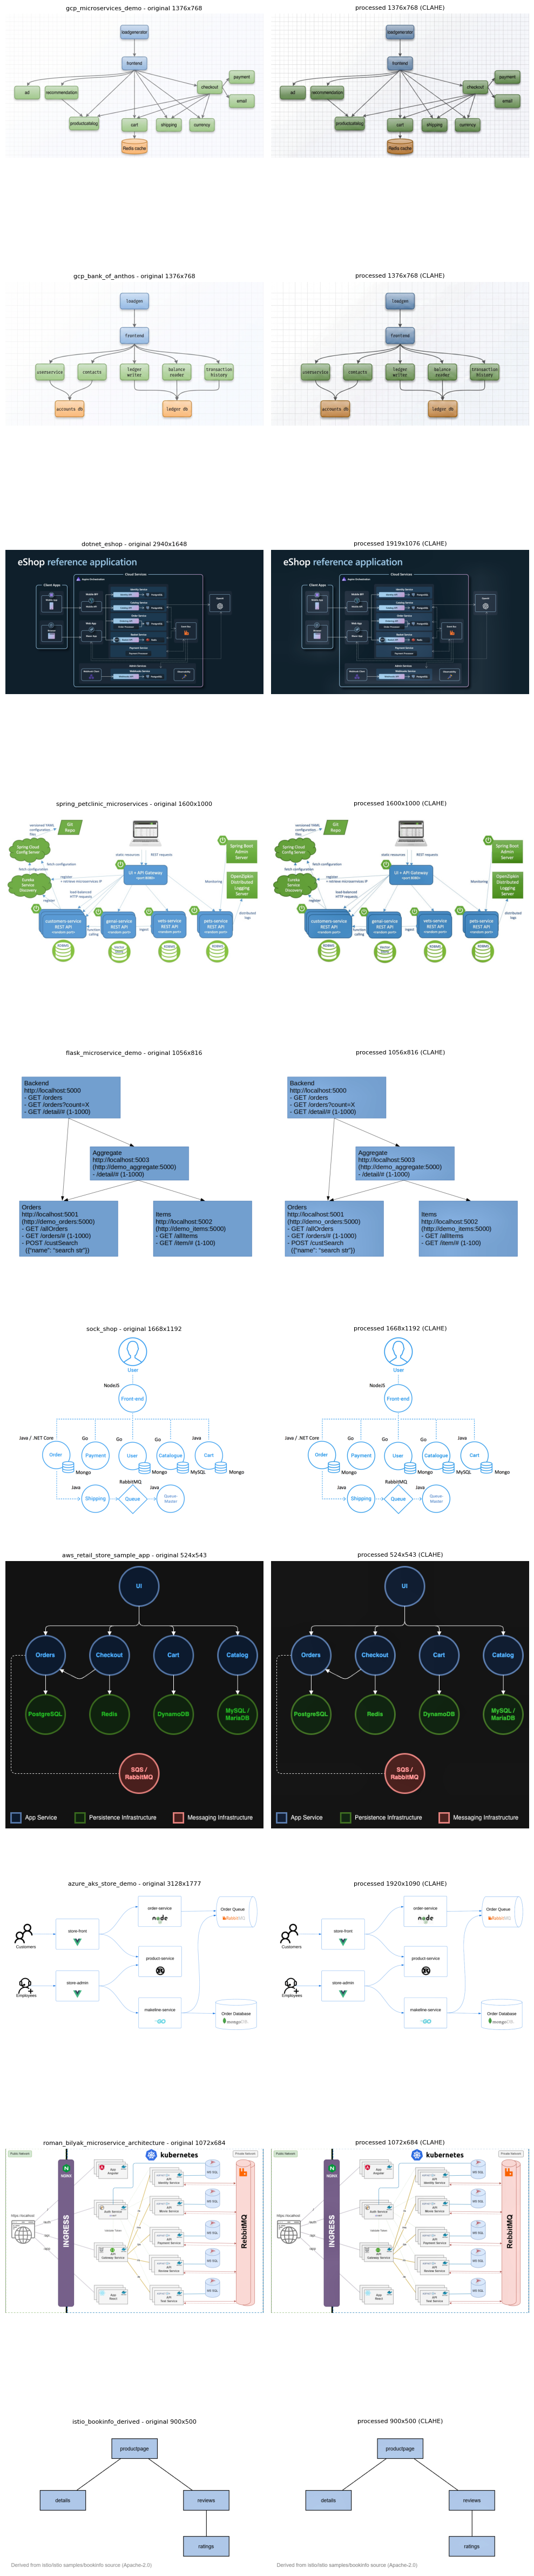

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(10, 2, figsize=(10, 50))

rows = []
for i, g in enumerate(graphs):
    raw_path = DIAGRAMS_DIR / Path(g.source).name
    original = preprocessor.load(str(raw_path))
    original_meta = compute_metadata(original, str(raw_path), channel_order="bgr")
    processed = preprocessor.preprocess(str(raw_path), color_mode="rgb")
    processed_meta = compute_metadata(processed, channel_order="rgb")

    axes[i, 0].imshow(preprocessor.to_rgb(original))
    axes[i, 0].set_title(f"{g.id} - original {original_meta.width}x{original_meta.height}", fontsize=8)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(processed)
    axes[i, 1].set_title(f"processed {processed_meta.width}x{processed_meta.height} (CLAHE)", fontsize=8)
    axes[i, 1].axis("off")

    rows.append({
        "diagram_id": g.id,
        "orig_size": f"{original_meta.width}x{original_meta.height}",
        "proc_size": f"{processed_meta.width}x{processed_meta.height}",
        "orig_blur": original_meta.blur_score,
        "proc_blur": processed_meta.blur_score,
        "orig_brightness": original_meta.mean_brightness,
        "proc_brightness": processed_meta.mean_brightness,
    })

plt.tight_layout()
plt.show()

In [3]:
header = f"{'diagram_id':<40} {'orig_size':>12} {'proc_size':>12} {'orig_blur':>10} {'proc_blur':>10}"
print(header)
print("-" * len(header))
resized_count = 0
sharper_count = 0
for r in rows:
    resized = r["orig_size"] != r["proc_size"]
    resized_count += resized
    sharper_count += r["proc_blur"] > r["orig_blur"]
    print(f"{r['diagram_id']:<40} {r['orig_size']:>12} {r['proc_size']:>12} {r['orig_blur']:>10.1f} {r['proc_blur']:>10.1f}")

print(f"\n{resized_count} of {len(rows)} diagrams were resized (longest side exceeded {preprocessor.max_size}px).")
print(f"CLAHE normalization increased the blur/sharpness score on {sharper_count} of {len(rows)} diagrams.")

diagram_id                                  orig_size    proc_size  orig_blur  proc_blur
----------------------------------------------------------------------------------------
gcp_microservices_demo                       1376x768     1376x768      703.6     1083.5
gcp_bank_of_anthos                           1376x768     1376x768      534.6      666.5
dotnet_eshop                                2940x1648    1919x1076      842.3     1112.2
spring_petclinic_microservices              1600x1000    1600x1000      532.8      622.3
flask_microservice_demo                      1056x816     1056x816     1559.0     1576.7
sock_shop                                   1668x1192    1668x1192      480.2      494.5
aws_retail_store_sample_app                   524x543      524x543     2445.8     2458.2
azure_aks_store_demo                        3128x1777    1920x1090      574.1      953.1
roman_bilyak_microservice_architecture       1072x684     1072x684     3904.7     4042.1
istio_bookinfo_derive